### NOAA OISST anoms with Spilhaus projection

In [1]:
# ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ #                         
#     Maurice F. Huguenin, mhuguenin-virchaux@geomar.de, 09. 10. 2026         #                                                
# ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ #
# % preamble ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ #                         
base = '/g/data/e14/mv7494/access-om2/archive/025deg_jra55_iaf/'
save = '/gxfs_home/geomar/smomw723/EddiesHC_figures/'

import cartopy
import cartopy.crs as ccrs
import cartopy.feature as cfeature
print("Cartopy:", cartopy.__version__) # I need version Cartopy: 0.25.0
import pyproj
print(pyproj.proj_version_str) # ... and PROJ: 9.6 or newer
import xarray as xr
import matplotlib.pyplot as plt # for matlab-like plotting    
import cartopy.feature as cfeature
import numpy as np
import xarray as xr
from scipy.interpolate import RegularGridInterpolator
from mpl_toolkits.axes_grid1.inset_locator import inset_axes # somehow I need this for the colour bar inside the plot

rotblau = [[0.4 , 0.  , 0.12], [0.47, 0.02, 0.13], [0.62, 0.07, 0.16], [0.66, 0.16, 0.2],
           [0.8 , 0.3 , 0.27], [0.87, 0.44, 0.35], [0.93, 0.58, 0.45], [0.96, 0.7 , 0.58], 
           [0.98, 0.8 , 0.71], [0.98, 0.94, 0.92], [0.93, 0.95, 0.96], [0.85, 0.91, 0.95],
           [0.76, 0.87, 0.93], [0.64, 0.8 , 0.89], [0.49, 0.72, 0.84], [0.34, 0.62, 0.79], 
           [0.23, 0.53, 0.74], [0.16, 0.44, 0.7] , [0.1 ,0.35, 0.6], [0.05, 0.24, 0.45], [0.02, 0.19, 0.38]]
myblue = [.19, .21, .58]

/gxfs_home/geomar/smomw723/miniforge3/envs/py3_std/lib/python3.10/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


Cartopy: 0.25.0
9.6.2


CPU times: user 512 ms, sys: 77.8 ms, total: 590 ms
Wall time: 614 ms


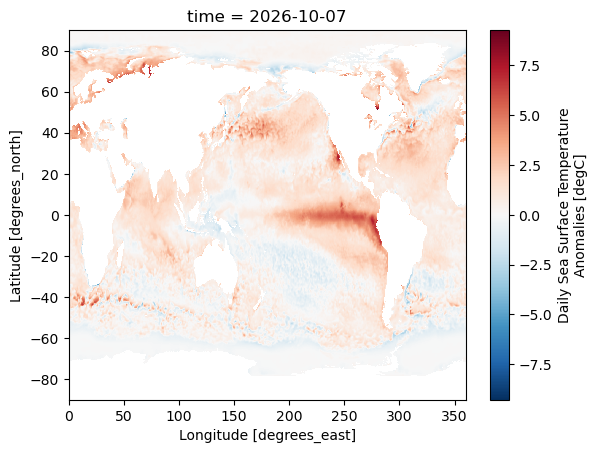

In [2]:
%%time
xr.open_mfdataset('/gxfs_home/geomar/smomw723/'+'sst.day.anom.2026.nc').anom[-1,:,:].plot() # take last time step

In [3]:
%%time
# open NOAA data set
ds = xr.open_dataset('/gxfs_home/geomar/smomw723/'+'sst.day.anom.2026.nc')
sst_anom = ds["anom"][-1,:,:]

lon = ds["lon"].values
lat = ds["lat"].values
data = sst_anom.values.astype(np.float32)

data = np.squeeze(data) # remove singleton dimensions

# preparing longitude axis in strictly increasing 0–360 coordinates
lon360 = lon % 360
order = np.argsort(lon360) # sort the longitude values in ascending order

lon_sorted = lon360[order]
data_sorted = data[:, order]

# removing any duplicate longitude coordinates, if present
lon_sorted, unique_idx = np.unique(lon_sorted, return_index=True)
data_sorted = data_sorted[:, unique_idx]

# add periodic copies at both ends to support interpolation across 0/360°
lon_ext = np.concatenate(([lon_sorted[-1] - 360], lon_sorted, [lon_sorted[0] + 360]))
data_ext = np.concatenate((data_sorted[:, -1:], data_sorted, data_sorted[:, :1]), axis=1)

# interpolate in geographic coordinates
interpolator = RegularGridInterpolator((lat, lon_ext), data_ext, method="linear", bounds_error=False, fill_value=np.nan)

spilhaus = ccrs.Spilhaus(rotation=45)
platecarree = ccrs.PlateCarree()

xmin, xmax = spilhaus.x_limits
ymin, ymax = spilhaus.y_limits

nx, ny = 1200, 1200
x = np.linspace(xmin, xmax, nx)
y = np.linspace(ymin, ymax, ny)
X, Y = np.meshgrid(x, y)

print('Transforming the data into the Spilhaus projection now')
ll = platecarree.transform_points(spilhaus, X, Y)

lon_target = ll[..., 0]; lat_target = ll[..., 1]

# next, I also need to wrap the target longitudes relative to the interpolation domain
lon_target = ((lon_target - lon_sorted[0]) % 360) + lon_sorted[0]

# now interpolating the SST anomalies onto the Spilhaus raster
points = np.column_stack((lat_target.ravel(), lon_target.ravel())) # flattening the two-dimensional target coordinate arrays into a list of points
spilhaus_data = interpolator(points)
spilhaus_data = spilhaus_data.reshape(lat_target.shape) # reshape into target shape

Transforming the data into the Spilhaus projection now
CPU times: user 6.32 s, sys: 70.4 ms, total: 6.39 s
Wall time: 6.4 s


### Plotting routine

CPU times: user 1min 16s, sys: 1.98 s, total: 1min 18s
Wall time: 1min 19s


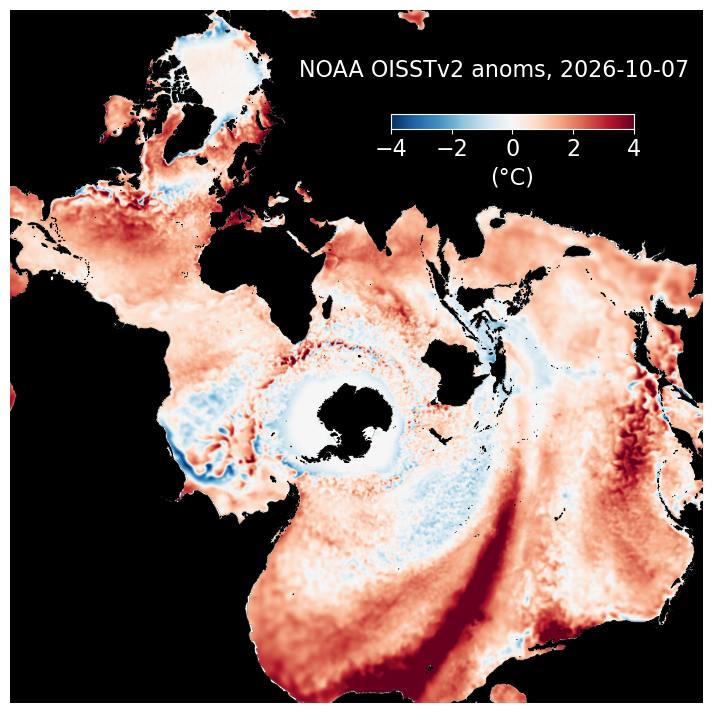

In [8]:
%%time
fig = plt.figure(figsize=(9,9)) # initialise figure
ax = plt.axes(projection=spilhaus) # using the spilhaus projection in cartopy
ax.set_global()

# make invalid pixels transparent
cmap = plt.get_cmap("RdBu_r").copy()
cmap.set_bad(alpha=0)

# here the key part, plotting the data --------------------------------------------------------------------------------------------------------------------------- # 
im = ax.imshow(spilhaus_data, origin="lower", extent=[xmin, xmax, ymin, ymax], cmap=cmap, 
               vmin=-4, vmax=4, interpolation="bilinear", transform=spilhaus, zorder=0) #
# ---------------------------------------------------------------------------------------------------------------------------------------------------------------- #

# land and coastline
ax.add_feature(cfeature.LAND.with_scale("50m"), facecolor='k', edgecolor="none", zorder=2)
ax.coastlines(resolution="50m", color="black", linewidth=0.5, zorder=3)

# adding a marker where I am currently on the map :-)
kiel_xy = spilhaus.transform_point(10.1228, 54.3233, platecarree) # I also need to transform this data point, otherwise it 
                                                                  # somehow shows up in Kerguelen haha
#ax.plot(kiel_xy[0], kiel_xy[1], marker="o", markersize=8, markerfacecolor=myblue, markeredgecolor="white", markeredgewidth=1.5, zorder=20)
#ax.text(kiel_xy[0] + 150e3, kiel_xy[1] + 150e3, 'I am here', color=myblue, fontsize=8, fontweight="bold", zorder=21)

ax.axis('off') # remove axis

# add title with automatic date from the data set
ax.text(0.98, 0.93, 'NOAA OISSTv2 anoms, ' + str(sst_anom.time.values)[:10], transform=ax.transAxes, ha="right", va="top", color='w', fontsize=16)

# colorbar directly below the text
cax = inset_axes(ax, width="35%", height="3%", loc="upper right",
                 bbox_to_anchor=(-.1, 0.15 ,1, 0.7), bbox_transform=ax.transAxes, borderpad=0)

# colorbar specifics to make it fancy
cbar = fig.colorbar(im, cax=cax, orientation="horizontal")
cbar.ax.tick_params(colors="w", labelsize=10)
cbar.outline.set_edgecolor("w")
cbar.ax.tick_params(labelsize=16)
cbar.set_label('(°C)', color='w', fontsize=16, labelpad=4)
cbar.set_ticks(np.linspace(-4,4, 5)) # have five ticks on the colour bar

# remove white border around figure that is automatically created by cartopy
#fig.patch.set_facecolor('k'); ax.set_facecolor('k'); ax.spines['geo'].set_visible(False)

# --- saving as 1000 dpi .PNG image in specified folder --------------------- #
plt.savefig(save + 'NOAA_OISST_spilhaus',                                    #
            dpi=1000, facecolor='k',  # remove 'w' border (make it black)    #
            edgecolor='k', orientation='landscape',                          #
            format=None, transparent=False, bbox_inches='tight',             #
            pad_inches=0.1, metadata=None)                                   #
# --- end of script -------------------------------------------------------- # 
# Wall time: 29.9 s